# ДЗ № 2. Прогнозирование продаж

**Курс:** «Прогнозирование временных рядов и обработка сигналов»  
**Товар:** `85099B` JUMBO BAG RED RETROSPOT  
**Источник:** [Online Retail, UCI](https://doi.org/10.24432/C5BW33), [ДЗ № 1](../hw1/hw1_sales_analysis.ipynb)

Цель — сравнить точность прогноза продаж в штуках для трёх моделей на дневной, недельной и месячной частотах. Сравниваются одни и те же модели на горизонтах **1, 7, 31, 61** для дня, **1, 4, 8** для недели и **1, 2** для месяца.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from forecasting import (
    EXPERIMENTS, MODELS, backtest, best_by_mae, describe_splits, evaluate, load_series,
)
from reporting import plot_first_paths, plot_forecasts, plot_metrics, save_figure, save_results

%matplotlib inline
pd.options.display.float_format = "{:,.3f}".format

OUTPUT = Path("results")
REBUILD_FROM_UCI = False

## 1. Подготовка данных

Из ДЗ № 1 сохраняются товар, показатель `Quantity` и правила очистки: исключены отмены, неположительные количества и цены, полные дубликаты. Реальные крупные заказы и истинные нули остаются в ряду. Снимок `input/series_85099B.csv` построен функцией `rebuild_series()` на основе кода ДЗ № 1. Установите `REBUILD_FROM_UCI = True`, чтобы повторить подготовку из исходного датасета.

| Частота | Временная сетка | Что прогнозируем |
|---|---|---|
| День | Вс–Пт. Шаг — один день на этой сетке | Штуки за день |
| Неделя | Вс–Сб, метка конца недели | Штуки в пересчёте на 6 рабочих дней |
| Месяц | Календарный месяц, метка начала месяца | Штуки в пересчёте на 26 рабочих дней |

Датасет обрывается 09.12.2011 в 12:50, поэтому исключены этот неполный день, последняя неделя и декабрь 2011. Первая неделя также неполная. Праздничные дни и полностью закрытая неделя сохраняют календарную позицию и `NaN` в факте. Для лагов и сглаживания на каждом срезе закрытые периоды заполняются только прошлым значением соответствующего дня недели для дневного ряда или предыдущей недели для недельного. При расчёте метрик закрытые периоды пропускаются. Интерполяцию и преобразования, рассчитанные в ДЗ № 1 по всему ряду, не переносим в обучение.

In [2]:
series = load_series(rebuild=REBUILD_FROM_UCI)
splits = describe_splits(series)
display(splits.set_index("frequency").T)

frequency,D,W,M
periods,320,52,12
observed,304,51,12
initial_train,220,35,8
initial_train_last_period,2011-08-14 00:00:00,2011-08-06 00:00:00,2011-07-01 00:00:00
test_periods,100,17,4
test_first_period,2011-08-15 00:00:00,2011-08-13 00:00:00,2011-08-01 00:00:00
test_last_period,2011-12-08 00:00:00,2011-12-03 00:00:00,2011-11-01 00:00:00
common_first_target,2011-10-24 00:00:00,2011-10-01 00:00:00,2011-09-01 00:00:00
common_last_target,2011-12-08 00:00:00,2011-12-03 00:00:00,2011-11-01 00:00:00
common_targets,40,10,3


**Протокол оценки.** Сохраняем последние 100 дневных, 17 недельных и 4 месячных позиций под тест. На каждом срезе обучаемся на расширяющейся истории, включая факты, которые к дате выпуска уже известны. Месячный срез соответствует концу месяца. Внутри траектории история не обновляется. В будущем модели известны только метки календарных периодов.

Для сравнения ровно $h$-го шага берём один набор целевых дат для всех $h$ данной частоты. Первая общая дата — та, до которой можно построить прогноз на максимальное требуемое число шагов из первого среза. Короткие прогнозы к той же дате выпускаются позднее. Получается 40 дневных, 10 недельных и 3 месячных целевых даты. Это сравнение с одинаковым фактом на каждом горизонте. Ошибки соседних дат могут быть зависимы, а итог по трём месяцам чувствителен к единичным наблюдениям.

## 2. Модели

| Модель | Спецификация |
|---|---|
| Naive | На дневном ряду повторяет последний цикл Вс–Пт. На недельном и месячном повторяет последнее значение. |
| ETS | Экспоненциальное сглаживание с аддитивным уровнем и затухающим аддитивным трендом ($phi=0{,}9$). Для дня добавлена сезонность длиной 6 шагов. Для устойчивости оптимизации ETS ряд делится на среднее обучения и возвращается в исходную шкалу при прогнозе. |
| Gradient Boosting | 80 деревьев с функцией потерь Хьюбера, шагом 0,05 и `random_state=42`. Дневные лаги 1, 2, 6, 12, среднее за 6 шагов и индикаторы дня недели. Недельные лаги 1, 2, 4 и среднее за 4 шага. Месячные лаги 1, 2 и среднее за 2 шага. |

Глубина деревьев 2 для дня и недели и 1 для месяца. В обучении бустинга используются только наблюдаемые целевые значения. Для шага $k>1$ модель получает собственные прогнозы предыдущих шагов в лагах и скользящем среднем. Все прогнозы ограничены снизу нулём. Настройки фиксированы и не подбираются по тестовым ошибкам.

## 3. Метрики

Пусть $e_i=hat y_i-y_i$ — ошибка ровно на $h$-м шаге. Все метрики ниже оцениваются на группах «частота, горизонт, модель».

- **MAE** — среднее $|e_i|$. Основной критерий выбора модели. Ошибка выражается в штуках и сохраняет линейный штраф за крупные промахи.
- **RMSE** — $sqrt{mathrm{mean}(e_i^2)}$. Крупные ошибки получают больший вес, что важно для крупных оптовых заказов.
- **MASE** — MAE, делённая на среднее $|y_t-y_{t-s}|$ по наблюдаемым парам первого обучающего окна. Для дня $s=6$, для недели и месяца $s=1$. Безразмерная метрика показывает ошибку относительно своего исторического масштаба на каждой частоте. MASE ниже 1 означает ошибку ниже этого масштаба. Для сравнения с тестовой наивной моделью используются её собственные тестовые строки.
- **PathMAE** — средняя абсолютная ошибка по всем доступным шагам $1,dots,h$ траекторий, оканчивающихся на общих целевых датах. Пересекающиеся траектории учитываются отдельно, поскольку выпускались в разные моменты. Метрика дополняет оценку $h$-го шага.

MAPE не используется: деление на факт не определено для нулевых дневных продаж. Между частотами сопоставляется прежде всего MASE, с учётом разных окон и состава ошибок.

In [3]:
paths = pd.concat([backtest(values, freq) for freq, values in series.items()], ignore_index=True)
metrics, points = evaluate(paths, series)
metrics = (
    metrics.assign(frequency=pd.Categorical(metrics["frequency"], list(EXPERIMENTS), ordered=True))
    .sort_values(["frequency", "horizon", "MAE"], ignore_index=True)
)
metrics["frequency"] = metrics["frequency"].astype("str")
winners = best_by_mae(metrics)

assert len(metrics) == len(MODELS) * sum(len(spec.horizons) for spec in EXPERIMENTS.values())
assert len(winners) == sum(len(spec.horizons) for spec in EXPERIMENTS.values())

save_results(OUTPUT, paths, points, metrics, splits)
display(metrics.set_index(["frequency", "horizon", "model"]))

n       MAE      RMSE  MASE  MASE_scale  \
frequency horizon model                                                         
D         1       Gradient Boosting  40   127.333   214.899 0.936     136.032   
                  ETS                40   140.647   207.706 1.034     136.032   
                  Naive              40   178.550   276.091 1.313     136.032   
          7       Gradient Boosting  40   126.092   219.512 0.927     136.032   
                  ETS                40   147.063   212.792 1.081     136.032   
                  Naive              40   204.525   319.922 1.504     136.032   
          31      Gradient Boosting  40   124.533   226.172 0.915     136.032   
                  ETS                40   134.004   213.973 0.985     136.032   
                  Naive              40   207.700   344.173 1.527     136.032   
          61      ETS                40   120.277   213.094 0.884     136.032   
                  Gradient Boosting  40   125.334   230.128 0.921     136.032   
                  Naive              40   157.750   249.763 1.160     136.032   
W         1       ETS                10   440.209   720.805 1.053     418.184   
                  Gradient Boosting  10   575.885   769.047 1.377     418.184   
                  Naive              10   833.300   994.481 1.993     418.184   
          4       ETS                10   442.195   720.955 1.057     418.184   
                  Gradient Boosting  10   520.658   712.742 1.245     418.184   
                  Naive              10   775.100 1,023.033 1.853     418.184   
          8       ETS                10   465.558   749.587 1.113     418.184   
                  Gradient Boosting  10   477.310   741.711 1.141     418.184   
                  Naive              10   670.600   912.738 1.604     418.184   
M         1       ETS                 3   673.635   823.857 0.828     813.392   
                  Naive               3   837.333   871.434 1.029     813.392   
                  Gradient Boosting   3 1,434.961 1,467.487 1.764     813.392   
          2       Naive               3   929.667 1,138.725 1.143     813.392   
                  ETS                 3   951.340 1,000.083 1.170     813.392   
                  Gradient Boosting   3 1,372.220 1,521.523 1.687     813.392   

                                     path_n   PathMAE  
frequency horizon model                                
D         1       Gradient Boosting      40   127.333  
                  ETS                    40   140.647  
                  Naive                  40   178.550  
          7       Gradient Boosting     280   127.995  
                  ETS                   280   144.022  
                  Naive                 280   182.439  
          31      Gradient Boosting    1240   149.669  
                  ETS                  1240   151.514  
                  Naive                1240   210.839  
          61      ETS                  2427   142.051  
                  Gradient Boosting    2427   144.921  
                  Naive                2427   193.162  
W         1       ETS                    10   440.209  
                  Gradient Boosting      10   575.885  
                  Naive                  10   833.300  
          4       ETS                    40   511.620  
                  Gradient Boosting      40   561.779  
                  Naive                  40   804.650  
          8       ETS                    80   496.479  
                  Gradient Boosting      80   521.700  
                  Naive                  80   743.562  
M         1       ETS                     3   673.635  
                  Naive                   3   837.333  
                  Gradient Boosting       3 1,434.961  
          2       Naive                   6 1,179.667  
                  ETS                     6   903.786  
                  Gradient Boosting       6 1,455.383

Таблица содержит 27 комбинаций. `n` — число фактических значений для основного расчёта, `MASE_scale` — масштаб ошибки по обучению. `path_n` — число пар по всем оцениваемым траекториям. Строки внутри каждого горизонта отсортированы по MAE.

## 4. Факт и прогноз

Ниже показаны траектории с максимальными горизонтами из первого среза для каждой частоты. На дневном графике разрыв факта соответствует закрытию магазина. Файл `results/forecast_paths.csv` хранит все траектории. Первые $h$ шагов каждой траектории дают прогноз длины $h$.

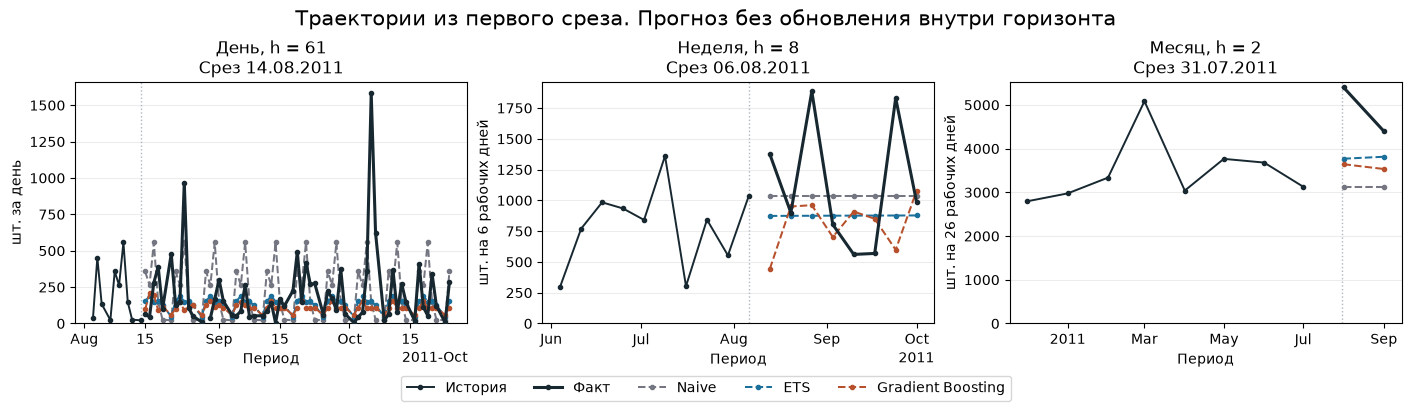

In [4]:
fig = plot_first_paths(paths, series)
save_figure(fig, OUTPUT, "first_paths")
plt.show()

На следующих графиках в каждой панели показан ровно $h$-й шаг прогноза. Точки с разными целевыми датами внутри панели относятся к разным выпускам. Чёрная линия факта повторяется по горизонтам одной частоты.

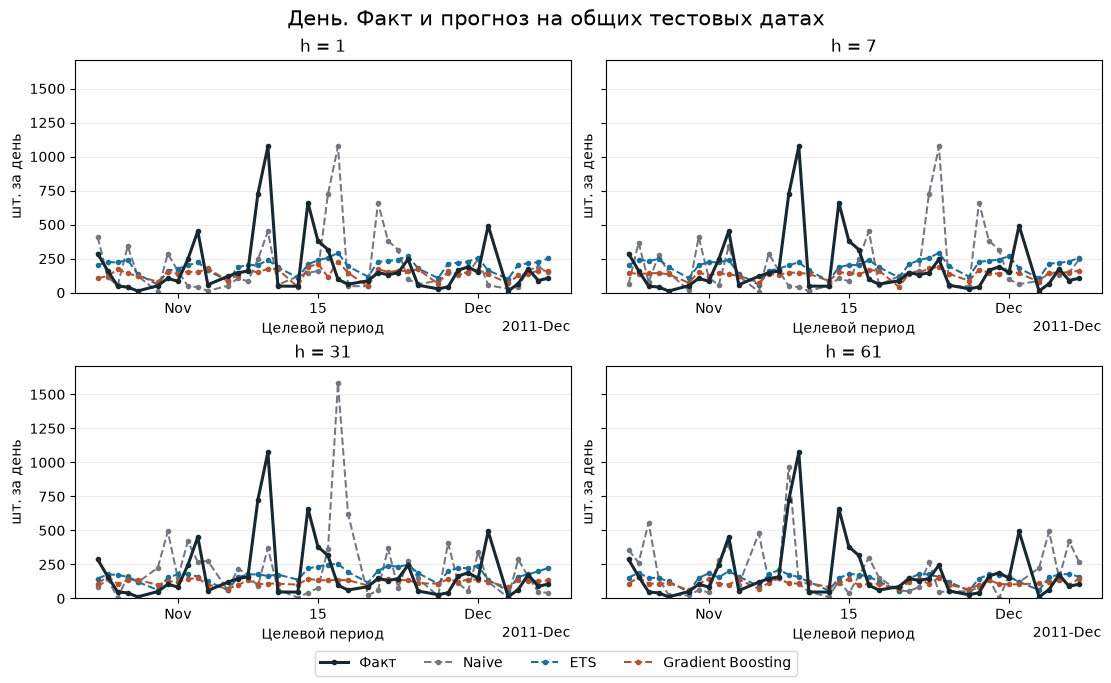

In [5]:
fig = plot_forecasts(points, "D")
save_figure(fig, OUTPUT, "forecasts_D")
plt.show()

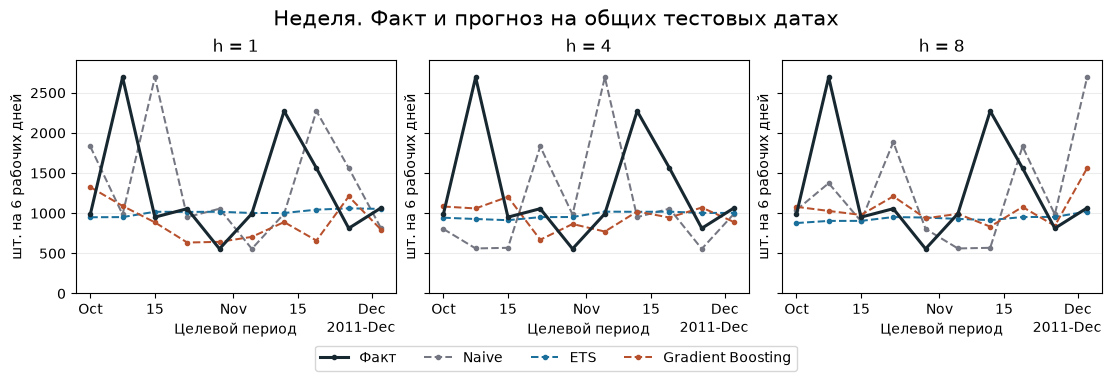

In [6]:
fig = plot_forecasts(points, "W")
save_figure(fig, OUTPUT, "forecasts_W")
plt.show()

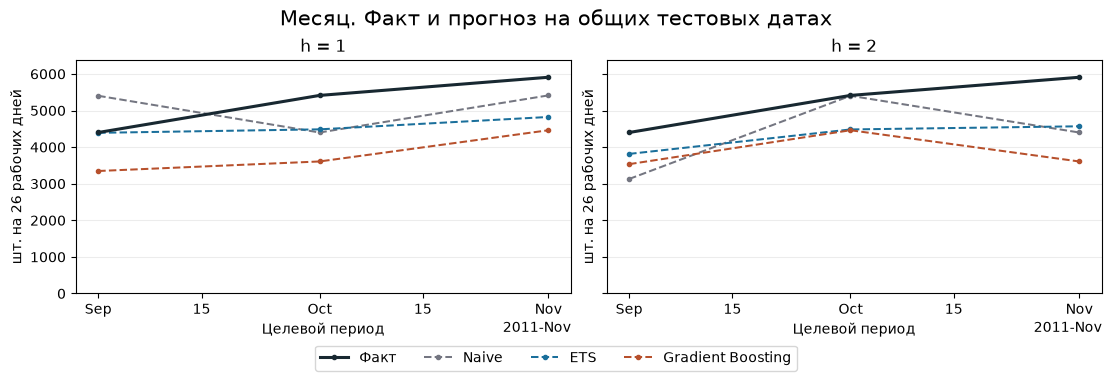

In [7]:
fig = plot_forecasts(points, "M")
save_figure(fig, OUTPUT, "forecasts_M")
plt.show()

## 5. Сравнение качества

Пунктир на уровне 1 отмечает исторический масштаб MASE. Отчёт о победителях использует MAE. Поскольку знаменатель MASE общий внутри частоты, ранжирование по этим двум метрикам совпадает.

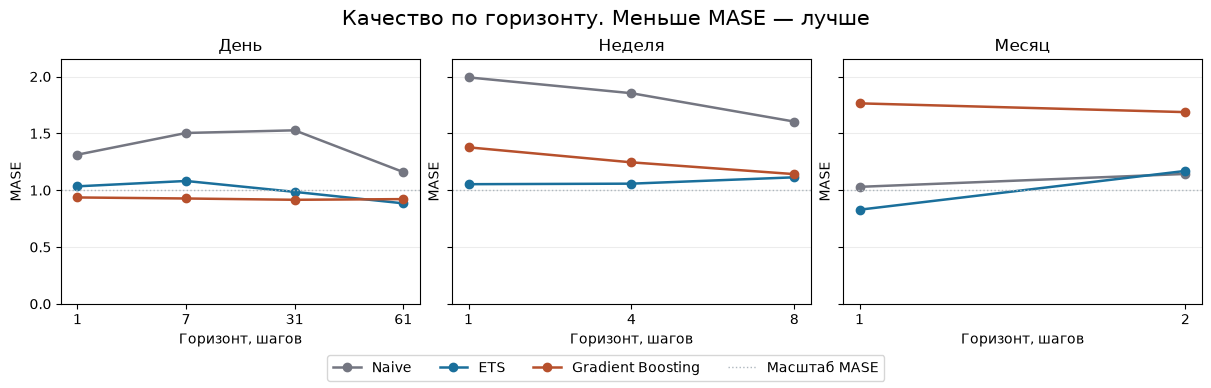

,frequency,horizon,model,n,MAE,RMSE,MASE,PathMAE
0,D,1,Gradient Boosting,40,127.333,214.899,0.936,127.333
1,D,7,Gradient Boosting,40,126.092,219.512,0.927,127.995
2,D,31,Gradient Boosting,40,124.533,226.172,0.915,149.669
3,D,61,ETS,40,120.277,213.094,0.884,142.051
4,W,1,ETS,10,440.209,720.805,1.053,440.209
5,W,4,ETS,10,442.195,720.955,1.057,511.620
6,W,8,ETS,10,465.558,749.587,1.113,496.479
7,M,1,ETS,3,673.635,823.857,0.828,673.635
8,M,2,Naive,3,929.667,"1,138.725",1.143,"1,179.667"


In [8]:
fig = plot_metrics(metrics)
save_figure(fig, OUTPUT, "mase_by_horizon")
plt.show()

display(winners[["frequency", "horizon", "model", "n", "MAE", "RMSE", "MASE", "PathMAE"]])

## 6. Выводы

- **День.** По MAE бустинг выигрывает на 1, 7 и 31 шаге (127,3 → 126,1 → 124,5 шт.). На 61 шаге лидирует ETS (120,3 шт., MASE 0,884). MAE бустинга держится в диапазоне 124,5–127,3 шт., а его RMSE растёт с 214,9 до 230,1 шт. ETS имеет наименьшую RMSE на всех дневных горизонтах. Среди 40 целевых дней встречались крупные всплески, например 1 074 шт. 10 ноября, и квадрат ошибки даёт таким дням больший вес.
- **Неделя.** ETS лидирует по MAE на 1, 4 и 8 шагах (440,2 → 442,2 → 465,6 шт. на 6 рабочих дней). Ошибка ETS немного растёт, а ошибка бустинга уменьшается с 575,9 до 477,3 шт. На 8 шагах разница между ними составляет 11,8 шт., около 2,5% от MAE ETS. Неделю до 8 октября с фактом 2 693 шт. все модели недооценили на всех трёх горизонтах. Модели использовали историю продаж без признаков будущих крупных заказов.
- **Месяц.** Для 1 шага лучший результат у ETS (673,6 шт. на 26 рабочих дней). На 2 шагах Naive немного лучше по MAE последнего шага (929,7 против 951,3 у ETS), а ETS лучше по RMSE и по всей траектории (PathMAE 903,8 против 1 179,7). На трёх общих целевых месяцах преимущество Naive по MAE предварительное. Месячный бустинг обучается всего на 6–9 строках с лагами и недооценивает высокие продажи октября и ноября.

Ошибка с ростом горизонта меняется по-разному. На этой выборке лучший месячный MAE растёт, недельный ETS ухудшается умеренно, а дневной MAE бустинга почти стабилен при росте RMSE. Тест охватывает один товар и конец 2011 года. Разные масштабы рядов учитывает MASE, но целевые интервалы и объём теста по частотам различаются. Для уверенного выбора на месячной частоте нужна более длинная история.